# Evaluation notebook

**Labels.**
- Distractor-only and distractor+gold responses: majority vote of three LLM judges (gpt-5.4-mini, gemini-3.1-flash-lite, qwen3.7-plus); tie-break ABSTAIN > CORRECT > INCORRECT.
- Gold-only responses: a single judge (gpt-5.4-mini); generated by `run_additional_gold_only.sh`.

**Confidence intervals.**
- The resampling unit is the query: 1,000 bootstrap resamples, seed 42.
- All responses of a resampled query stay together, so differences between tiers, prompts, and conditions are paired.
- Reported as the 2.5th and 97.5th percentiles.

In [1]:
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.discrete.conditional_models import ConditionalLogit

warnings.filterwarnings('ignore')

REPO_ROOT  = Path('..').resolve()
DATA_DIR   = REPO_ROOT / 'data'
JUDGE_DIR  = DATA_DIR / 'judge step'
GOLD_DIR   = DATA_DIR / 'additional' / 'judge'
EVAL_CSV   = DATA_DIR / 'rag_eval_multilingual_eval.csv'
OUT_TABLES = REPO_ROOT / 'outputs' / 'paper' / 'tables'
OUT_FIGS   = REPO_ROOT / 'outputs' / 'paper' / 'figures'
OUT_TABLES.mkdir(parents=True, exist_ok=True)
OUT_FIGS.mkdir(parents=True, exist_ok=True)

SEED, N_BOOT = 42, 1000
PROVIDERS    = ['openai', 'gemini', 'qwen']
LABELS       = ['ABSTAIN', 'INCORRECT', 'CORRECT']
VALID_LABELS = set(LABELS)
DIFFICULTY_ORDER  = ['easy', 'medium', 'hard']
DIFFICULTY_LABELS = {'easy': 'Easy', 'medium': 'Medium', 'hard': 'Hard'}
PROMPTS = ['simple', 'advanced']
QKEYS   = ['language', 'query_id']
MERGE_KEYS = ['language', 'query_id', 'distractor_id']

# file key -> model name
MODEL_MAP = {
    'claude_sonnet4':      'claude-sonnet-4.5',
    'gemini31_flash_lite': 'gemini-3.1-flash-lite',
    'gpt54mini':           'gpt-5.4-mini',
    'gemma4':              'gemma4:26b',
    'qwen36':              'qwen3.6:27b',
    'gemma4_26b':          'gemma4:26b',
    'qwen3.6:27b':         'qwen3.6:27b',
}
MODEL_ORDER       = ['gpt-5.4-mini', 'gemma4:26b', 'qwen3.6:27b', 'claude-sonnet-4.5', 'gemini-3.1-flash-lite']
TABLE_MODEL_ORDER = ['gpt-5.4-mini', 'claude-sonnet-4.5', 'gemini-3.1-flash-lite', 'gemma4:26b', 'qwen3.6:27b']
OPEN_MODELS       = ['gemma4:26b', 'qwen3.6:27b']
MODEL_SHORT = {
    'gpt-5.4-mini':          'GPT-5.4-mini',
    'gemma4:26b':            'Gemma4 26B',
    'qwen3.6:27b':           'Qwen3.6 27B',
    'claude-sonnet-4.5':     'Claude Son. 4.5',
    'gemini-3.1-flash-lite': 'Gemini 3.1 FL',
}
MODEL_LATEX = {
    'gpt-5.4-mini':          r'GPT-5.4-mini',
    'claude-sonnet-4.5':     r'Cl.\ Son.\ 4.5',
    'gemini-3.1-flash-lite': r'Gem.\ 3.1~FL',
    'gemma4:26b':            r'Gemma4~26B',
    'qwen3.6:27b':           r'Qwen3.6~27B',
}

# ── Figure style (unchanged from the review version) ─────────────────────────
MODEL_COLORS = {
    'gpt-5.4-mini':          '#0072B2',
    'gemma4:26b':            '#E69F00',
    'qwen3.6:27b':           '#009E73',
    'claude-sonnet-4.5':     '#CC79A7',
    'gemini-3.1-flash-lite': '#D55E00',
}
DISPLAY_LS = {
    'gpt-5.4-mini': '-', 'gemini-3.1-flash-lite': '-', 'claude-sonnet-4.5': '-',
    'gemma4:26b': '--', 'qwen3.6:27b': '--',
}
MARKER_SHAPES = {
    'gpt-5.4-mini': 'o', 'gemini-3.1-flash-lite': 's', 'claude-sonnet-4.5': 'D',
    'gemma4:26b': '^', 'qwen3.6:27b': 'v',
}
plt.rcParams.update({
    'font.family': 'DejaVu Serif', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.alpha': 0.28, 'grid.linestyle': '--',
    'figure.dpi': 150,
})

In [2]:
def majority_vote(labels):
    """Majority vote; tie-break ABSTAIN > CORRECT > INCORRECT."""
    c = Counter(labels)
    top = max(c.values())
    winners = [l for l, n in c.items() if n == top]
    if len(winners) == 1:
        return winners[0]
    return next(p for p in ('ABSTAIN', 'CORRECT', 'INCORRECT') if p in winners)


def read_judge(path, keys):
    df = pd.read_csv(path, usecols=lambda c: c in keys + ['difficulty', 'judge_label'],
                     dtype={'query_id': str, 'distractor_id': str})
    df['judge_label'] = df['judge_label'].str.upper().str.strip()
    return df


def merge_providers(fname, subdir=''):
    """Three judge files for one model × prompt → one row per response with the majority label."""
    merged = None
    for prov in PROVIDERS:
        d = read_judge(JUDGE_DIR / prov / subdir / fname, MERGE_KEYS).rename(columns={'judge_label': f'label_{prov}'})
        merged = d if merged is None else merged.merge(d, on=MERGE_KEYS + ['difficulty'], how='inner')
    label_cols = [f'label_{p}' for p in PROVIDERS]
    n_all = len(merged)
    merged = merged[merged[label_cols].isin(VALID_LABELS).all(axis=1)].copy()
    merged['label'] = [majority_vote(r) for r in merged[label_cols].values]
    return merged, n_all


def load_main():
    records, n_all = [], 0
    for mkey in ['claude_sonnet4', 'gemini31_flash_lite', 'gpt54mini', 'gemma4', 'qwen36']:
        for prompt, suffix in [('simple', ''), ('advanced', '_advanced')]:
            merged, n = merge_providers(f'multilingual_{mkey}_answers{suffix}__judged.csv')
            n_all += n
            records.append(merged.assign(model=MODEL_MAP[mkey], prompt=prompt))
    return pd.concat(records, ignore_index=True), n_all


def load_robustness():
    records = []
    for mkey in ['gemma4_26b', 'qwen3.6:27b']:
        for prompt in PROMPTS:
            merged, _ = merge_providers(f'{mkey}__{prompt}__distractor_plus_gold__judged.csv', subdir='withgold')
            records.append(merged.assign(model=MODEL_MAP[mkey], prompt=prompt))
    return pd.concat(records, ignore_index=True)


def load_gold_only():
    """Gold-only control: single judge (gpt-5.4-mini)."""
    records = []
    for mkey in ['gemma4_26b', 'qwen3.6:27b']:
        for prompt in PROMPTS:
            d = read_judge(GOLD_DIR / 'openai' / f'{mkey}__{prompt}__gold_only__judged.csv', QKEYS)
            d = d[d['judge_label'].isin(VALID_LABELS)].rename(columns={'judge_label': 'label'})
            records.append(d.assign(model=MODEL_MAP[mkey], prompt=prompt))
    return pd.concat(records, ignore_index=True)


eval_df = pd.read_csv(EVAL_CSV, dtype={'query_id': str, 'distractor_id': str})
QUERIES = pd.MultiIndex.from_frame(eval_df[QKEYS].drop_duplicates().sort_values(QKEYS))

df_main, n_main_all = load_main()
df_rob  = load_robustness()
df_gold = load_gold_only()
print(f'queries: {len(QUERIES):,}   distractor-only: {len(df_main):,} of {n_main_all:,}   '
      f'distractor+gold: {len(df_rob):,}   gold-only: {len(df_gold):,}')

queries: 1,400   distractor-only: 41,971 of 42,000   distractor+gold: 16,786   gold-only: 5,600


## Query-level bootstrap

Each experiment is pivoted to one row per query, with one column per (model, prompt[, tier]) and label. The same 1,000 resamples of the 1,400 queries are applied to every column, so all differences are paired.

In [3]:
RNG = np.random.default_rng(SEED)
BOOT_IDX = RNG.integers(0, len(QUERIES), size=(N_BOOT, len(QUERIES)))


def wide(df, cols):
    """label -> (queries × cols) 0/1 matrix; NaN where a response is missing."""
    out = {}
    for lbl in LABELS:
        w = df.assign(v=(df['label'] == lbl).astype(float)).pivot_table(
            index=QKEYS, columns=cols, values='v', aggfunc='first')
        out[lbl] = w.reindex(QUERIES)
    return out


class Est:
    """Point estimate plus its bootstrap distribution; supports + - * / and averaging."""
    def __init__(self, point, boots):
        self.point, self.boots = float(point), np.asarray(boots, dtype=float)
    def __add__(self, o): return Est(self.point + o.point, self.boots + o.boots)
    def __sub__(self, o): return Est(self.point - o.point, self.boots - o.boots)
    def __truediv__(self, o): return Est(self.point / o.point, self.boots / o.boots)
    def __mul__(self, k): return Est(self.point * k, self.boots * k)
    @property
    def lo(self): return float(np.nanpercentile(self.boots, 2.5))
    @property
    def hi(self): return float(np.nanpercentile(self.boots, 97.5))
    @property
    def significant(self): return self.lo > 0 or self.hi < 0
    def fmt(self): return f'{self.point:.1f} [{self.lo:.1f}, {self.hi:.1f}]'


def mean_est(ests):
    return Est(np.mean([e.point for e in ests]), np.mean([e.boots for e in ests], axis=0))


def col_est(vec, idx=BOOT_IDX):
    v = np.asarray(vec, dtype=float)
    return Est(100 * np.nanmean(v), 100 * np.nanmean(v[idx], axis=1))


W_main = wide(df_main, ['model', 'prompt', 'difficulty'])
W_rob  = wide(df_rob,  ['model', 'prompt', 'difficulty'])
W_gold = wide(df_gold, ['model', 'prompt'])

_cache = {}
def rate(W, name, lbl, *key):
    k = (name, lbl) + key
    if k not in _cache:
        _cache[k] = col_est(W[lbl][key].to_numpy())
    return _cache[k]

main = lambda lbl, m, p, d: rate(W_main, 'main', lbl, m, p, d)
rob  = lambda lbl, m, p, d: rate(W_rob, 'rob', lbl, m, p, d)
gold = lambda lbl, m, p:    rate(W_gold, 'gold', lbl, m, p)
print('bootstrap ready')

bootstrap ready


## Main results (distractor-only)

In [4]:
rows = []
for m in TABLE_MODEL_ORDER:
    for p in PROMPTS:
        for d in DIFFICULTY_ORDER:
            row = {'model': m, 'prompt': p, 'difficulty': d}
            for lbl in LABELS:
                e = main(lbl, m, p, d)
                row[f'{lbl}_pct'], row[f'{lbl}_lo'], row[f'{lbl}_hi'] = round(e.point, 1), round(e.lo, 1), round(e.hi, 1)
            rows.append(row)
tbl_main = pd.DataFrame(rows)
tbl_main.to_csv(OUT_TABLES / 'table2_main.csv', index=False)

hw = max(((tbl_main[f'{l}_hi'] - tbl_main[f'{l}_lo']) / 2).max() for l in LABELS)
print(f'Table 2: max 95% CI half-width = {hw:.2f} pp')


def latex_main(df, max_hw):
    lines = [r'\begin{table*}[t]', r'\centering',
             r'\caption{Main results (distractor-only) by model, prompt, and distractor difficulty. '
             r'A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. Values are percentages of the LLMs-as-a-Judge '
             rf'majority-vote label, aggregated over all 14 languages; all 95\% query-level bootstrap CI half-widths '
             rf'are below {np.ceil(max_hw * 10) / 10:.1f}\,pp. P: S\,=\,Simple, Adv\,=\,Advanced.}}',
             r'\label{tab:main_results}', r'\setlength{\tabcolsep}{4pt}', r'\begin{tabular}{ll ccc ccc ccc}',
             r'& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\',
             r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}',
             r'\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\', r'\midrule']
    for mi, m in enumerate(TABLE_MODEL_ORDER):
        for pi, p in enumerate(PROMPTS):
            cells = []
            for d in DIFFICULTY_ORDER:
                r = df[(df.model == m) & (df.prompt == p) & (df.difficulty == d)].iloc[0]
                cells += [f"{r['ABSTAIN_pct']:.1f}", f"{r['INCORRECT_pct']:.1f}", f"{r['CORRECT_pct']:.1f}"]
            p_label = 'S' if p == 'simple' else 'Adv'
            if pi == 0:
                lines.append(f'\\multirow{{2}}{{*}}{{{MODEL_LATEX[m]}}}')
            lines.append(f'  & {p_label} & ' + ' & '.join(cells) + r' \\')
            if pi == 1 and mi < len(TABLE_MODEL_ORDER) - 1:
                lines.append(r'\midrule')
    lines += [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(lines)


tex = latex_main(tbl_main, hw)
(OUT_TABLES / 'table2_main.tex').write_text(tex)
print(tex)

Table 2: max 95% CI half-width = 2.65 pp
\begin{table*}[t]
\centering
\caption{Main results (distractor-only) by model, prompt, and distractor difficulty. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. Values are percentages of the LLMs-as-a-Judge majority-vote label, aggregated over all 14 languages; all 95\% query-level bootstrap CI half-widths are below 2.7\,pp. P: S\,=\,Simple, Adv\,=\,Advanced.}
\label{tab:main_results}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{ll ccc ccc ccc}
& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}
\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\
\midrule
\multirow{2}{*}{GPT-5.4-mini}
  & S & 47.5 & 45.1 & 7.4 & 38.3 & 48.6 & 13.1 & 30.5 & 47.2 & 22.3 \\
  & Adv & 83.3 & 15.7 & 1.0 & 74.8 & 18.9 & 6.3 & 65.1 & 22.2 & 12.7 \\
\midrule
\multirow{2}{*}{Cl.\ Son.\ 4.5}
  & S & 84.8 & 13.8 & 1.4 & 73.2 & 21.7 & 5.1 & 61

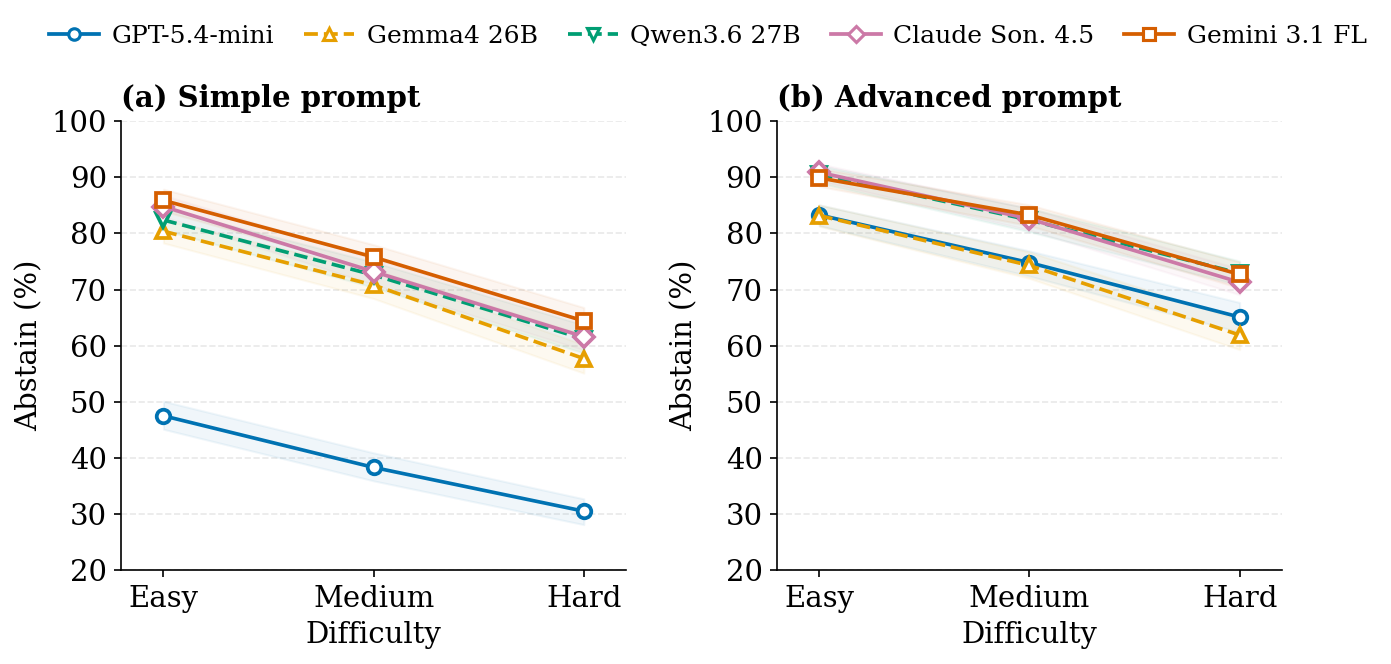

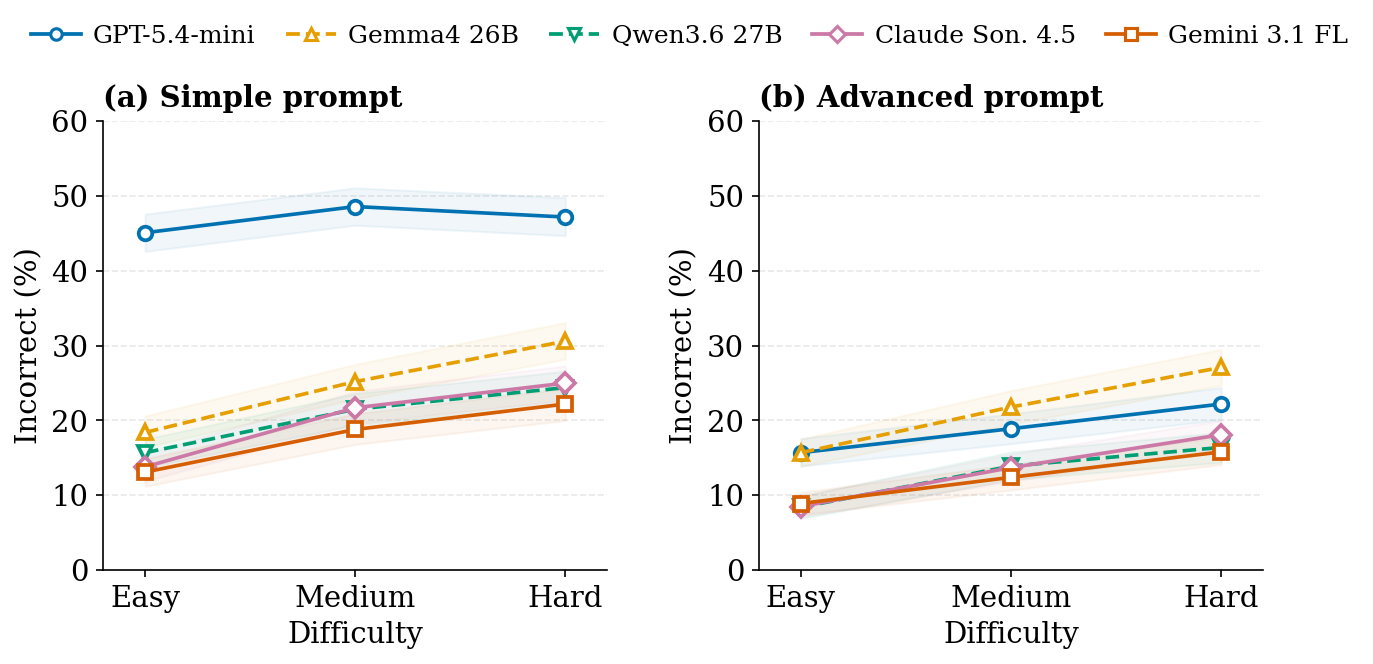

In [5]:
def _axis_range(metric, pad=1, step=10):
    lo, hi = tbl_main[f'{metric}_lo'].min(), tbl_main[f'{metric}_hi'].max()
    ymin = max(0, int(np.floor((lo - pad) / step)) * step)
    ymax = min(100, int(np.ceil((hi + pad) / step)) * step)
    return (ymin, ymax), list(range(ymin, ymax + step, step))


x_pos, x_labels = np.arange(3), [DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER]


def _line_panel(ax, metric, prompt, ylim, yticks):
    sub = tbl_main[tbl_main['prompt'] == prompt]
    for m in MODEL_ORDER:
        mdf = sub[sub['model'] == m].set_index('difficulty').loc[DIFFICULTY_ORDER]
        ax.plot(x_pos, mdf[f'{metric}_pct'].values, color=MODEL_COLORS[m], linestyle=DISPLAY_LS[m],
                linewidth=1.75, marker=MARKER_SHAPES[m], markersize=6.5,
                markerfacecolor='white', markeredgewidth=1.8, zorder=4)
        ax.fill_between(x_pos, mdf[f'{metric}_lo'].values, mdf[f'{metric}_hi'].values,
                        color=MODEL_COLORS[m], alpha=0.06, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.set_xlabel('Difficulty', labelpad=4, fontsize=14)
    ax.set_xlim(-0.2, 2.2)
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    ax.tick_params(axis='y', labelsize=14)


def _legend_handles():
    return [mlines.Line2D([], [], color=MODEL_COLORS[m], linestyle=DISPLAY_LS[m], linewidth=1.8,
                          marker=MARKER_SHAPES[m], markersize=5.5, markerfacecolor='white',
                          markeredgewidth=1.5, label=MODEL_SHORT[m]) for m in MODEL_ORDER]


for metric, ylabel, fname in [('ABSTAIN', 'Abstain (%)', 'fig3_abstain_by_difficulty'),
                              ('INCORRECT', 'Incorrect (%)', 'fig4_incorrect_by_difficulty')]:
    ylim, yticks = _axis_range(metric)
    fig, (ax_s, ax_a) = plt.subplots(1, 2, figsize=(8.5, 4.4), gridspec_kw=dict(wspace=0.30))
    fig.subplots_adjust(left=0.08, right=0.99, top=0.82, bottom=0.14)
    for ax, prompt, title in [(ax_s, 'simple', '(a) Simple prompt'), (ax_a, 'advanced', '(b) Advanced prompt')]:
        _line_panel(ax, metric, prompt, ylim, yticks)
        ax.set_ylabel(ylabel, labelpad=4, fontsize=14)
        ax.set_title(title, fontsize=14, fontweight='bold', pad=7, loc='left')
    fig.legend(handles=_legend_handles(), loc='upper center', ncol=5, fontsize=12, frameon=False,
               bbox_to_anchor=(0.54, 1.0), handlelength=2.0, handletextpad=0.5, columnspacing=1.2)
    fig.savefig(OUT_FIGS / f'{fname}.pdf', bbox_inches='tight')
    fig.savefig(OUT_FIGS / f'{fname}.png', dpi=300, bbox_inches='tight')
    plt.show()

Averages over the five models; paired query-level CIs.

In [6]:
avg = lambda lbl, p, d: mean_est([main(lbl, m, p, d) for m in MODEL_ORDER])
avg_all = lambda lbl, p: mean_est([avg(lbl, p, d) for d in DIFFICULTY_ORDER])

print('Average over models (Easy → Hard):')
for p in PROMPTS:
    for lbl in ['ABSTAIN', 'INCORRECT']:
        e, h = avg(lbl, p, 'easy'), avg(lbl, p, 'hard')
        print(f'  {p:8s} {lbl:9s} easy {e.fmt()}  hard {h.fmt()}  Hard−Easy {(h - e).fmt()}')

print('\nIncorrect, all tiers (abstract, §5.2):')
s, a = avg_all('INCORRECT', 'simple'), avg_all('INCORRECT', 'advanced')
print(f'  simple {s.fmt()}  advanced {a.fmt()}  Advanced−Simple {(a - s).fmt()}')

print('\nHard − Easy per model (paired):')
rows = []
for m in TABLE_MODEL_ORDER:
    for p in PROMPTS:
        da = main('ABSTAIN', m, p, 'hard') - main('ABSTAIN', m, p, 'easy')
        di = main('INCORRECT', m, p, 'hard') - main('INCORRECT', m, p, 'easy')
        rows.append({'model': m, 'prompt': p, 'abstain': da.fmt(), 'abstain_sig': da.significant,
                     'incorrect': di.fmt(), 'incorrect_sig': di.significant})
hard_easy = pd.DataFrame(rows)
hard_easy.to_csv(OUT_TABLES / 'hard_minus_easy_by_model.csv', index=False)
print(hard_easy.to_string(index=False))
print(f"\nAbstention decrease significant: {hard_easy.abstain_sig.sum()}/10;  incorrect increase significant: {hard_easy.incorrect_sig.sum()}/10")

print('\nAdvanced − Simple per model (all tiers):')
for m in TABLE_MODEL_ORDER:
    da = mean_est([main('ABSTAIN', m, 'advanced', d) for d in DIFFICULTY_ORDER]) - mean_est([main('ABSTAIN', m, 'simple', d) for d in DIFFICULTY_ORDER])
    di = mean_est([main('INCORRECT', m, 'advanced', d) for d in DIFFICULTY_ORDER]) - mean_est([main('INCORRECT', m, 'simple', d) for d in DIFFICULTY_ORDER])
    print(f'  {m:22s} abstain {da.fmt():22s} incorrect {di.fmt()}')

abst = tbl_main.groupby('model')['ABSTAIN_pct'].mean().sort_values(ascending=False)
print(f'\nAverage abstention by model: highest {abst.index[0]} {abst.iloc[0]:.0f}%, lowest {abst.index[-1]} {abst.iloc[-1]:.0f}%')
ha = tbl_main[(tbl_main.difficulty == 'hard') & (tbl_main.prompt == 'advanced')]['INCORRECT_pct']
print(f'Incorrect on Hard, advanced prompt: mean {ha.mean():.0f}%, max {ha.max():.0f}%')
hs = tbl_main[(tbl_main.difficulty == 'hard') & (tbl_main.prompt == 'simple')]['INCORRECT_pct']
print(f'Incorrect on Hard, simple prompt (§6.2): {hs.min():.0f}–{hs.max():.0f}%')

Average over models (Easy → Hard):
  simple   ABSTAIN   easy 76.2 [74.6, 77.9]  hard 55.1 [53.0, 57.1]  Hard−Easy -21.1 [-23.5, -18.7]
  simple   INCORRECT easy 21.2 [19.6, 22.8]  hard 29.9 [28.0, 31.7]  Hard−Easy 8.6 [6.7, 10.8]
  advanced ABSTAIN   easy 87.6 [86.3, 89.0]  hard 68.8 [66.8, 70.8]  Hard−Easy -18.8 [-21.0, -16.5]
  advanced INCORRECT easy 11.4 [10.1, 12.8]  hard 19.9 [18.3, 21.5]  Hard−Easy 8.5 [6.6, 10.4]

Incorrect, all tiers (abstract, §5.2):
  simple 26.1 [24.8, 27.3]  advanced 15.8 [14.7, 16.8]  Advanced−Simple -10.3 [-10.8, -9.7]

Hard − Easy per model (paired):
                model   prompt              abstain  abstain_sig        incorrect  incorrect_sig
         gpt-5.4-mini   simple -17.0 [-20.5, -13.9]         True  2.1 [-1.2, 5.4]          False
         gpt-5.4-mini advanced -18.2 [-21.0, -15.5]         True   6.5 [4.0, 9.1]           True
    claude-sonnet-4.5   simple -23.2 [-26.0, -20.2]         True 11.2 [8.6, 14.1]           True
    claude-sonnet-4.5 

## Difficulty-score check

The three distractors of each query are re-ranked by a single signal (lowest = easy). Rates are averaged over models. Distractor length is checked with a conditional logistic regression (one stratum per query × model × prompt) that controls for compound similarity.

In [7]:
feat = eval_df[MERGE_KEYS + ['tfidf_sim', 'semantic_sim', 'compound_sim']].copy()
feat['log_len'] = np.log(eval_df['distractor_text'].str.len())

rows = []
for score, name in [('tfidf_sim', 'lexical'), ('semantic_sim', 'semantic'), ('compound_sim', 'compound'), ('log_len', 'length')]:
    tier = feat.groupby(QKEYS)[score].rank(method='first').map({1: 'easy', 2: 'medium', 3: 'hard'})
    d = df_main.merge(feat[MERGE_KEYS].assign(tier=tier), on=MERGE_KEYS)
    for p in PROMPTS:
        r = d[d.prompt == p].groupby('tier')['label'].value_counts(normalize=True).unstack() * 100
        rows.append({'tiers_by': name, 'prompt': p,
                     **{f'A_{t}': round(r.loc[t, 'ABSTAIN'], 1) for t in DIFFICULTY_ORDER},
                     **{f'I_{t}': round(r.loc[t, 'INCORRECT'], 1) for t in DIFFICULTY_ORDER}})
score_tiers = pd.DataFrame(rows)
score_tiers.to_csv(OUT_TABLES / 'difficulty_score_check.csv', index=False)
print(score_tiers.to_string(index=False))

z = feat.copy()
for c in ['compound_sim', 'log_len']:
    z[c] = z.groupby('language')[c].transform(lambda s: (s - s.mean()) / s.std())
reg = df_main.merge(z[MERGE_KEYS + ['compound_sim', 'log_len']], on=MERGE_KEYS)
reg['answered'] = (reg['label'] != 'ABSTAIN').astype(int)
reg['stratum'] = reg['language'] + '|' + reg['query_id'] + '|' + reg['model'] + '|' + reg['prompt']
res = ConditionalLogit(reg['answered'], reg[['compound_sim', 'log_len']], groups=reg['stratum']).fit(disp=0)
ci = np.exp(res.conf_int())
print(f"\nAnswering vs. length, compound similarity held fixed: OR per SD = {np.exp(res.params['log_len']):.2f} "
      f"[{ci.loc['log_len', 0]:.2f}, {ci.loc['log_len', 1]:.2f}] (OR < 1: longer distractors are answered less often)")

tiers_by   prompt  A_easy  A_medium  A_hard  I_easy  I_medium  I_hard
 lexical   simple    75.7      66.1    55.7    21.9      27.2    29.3
 lexical advanced    87.3      79.4    69.2    11.7      16.2    19.6
semantic   simple    76.4      65.9    55.1    20.8      27.4    30.1
semantic advanced    87.8      79.5    68.5    11.1      16.1    20.2
compound   simple    76.2      66.2    55.1    21.2      27.2    29.9
compound advanced    87.6      79.5    68.8    11.4      16.1    19.9
  length   simple    64.2      65.4    67.9    27.5      26.4    24.3
  length advanced    78.1      77.7    80.0    16.1      16.6    14.8



Answering vs. length, compound similarity held fixed: OR per SD = 0.88 [0.85, 0.91] (OR < 1: longer distractors are answered less often)


## Error rate among non-correct responses

I / (A + I) per cell: how often a model answers incorrectly rather than abstaining when it does not answer correctly.

In [8]:
err = lambda m, p, d: main('INCORRECT', m, p, d) / (main('INCORRECT', m, p, d) + main('ABSTAIN', m, p, d)) * 100

rows = []
for m in TABLE_MODEL_ORDER:
    for p in PROMPTS:
        es = {d: err(m, p, d) for d in DIFFICULTY_ORDER}
        rows.append({'model': m, 'prompt': p, **{d: round(es[d].point, 1) for d in DIFFICULTY_ORDER},
                     'max_half_width': max((e.hi - e.lo) / 2 for e in es.values()),
                     'hard_minus_easy': (es['hard'] - es['easy']).fmt(),
                     'sig': (es['hard'] - es['easy']).significant})
tbl_err = pd.DataFrame(rows)
tbl_err.to_csv(OUT_TABLES / 'table3_error_among_noncorrect.csv', index=False)
print(tbl_err.to_string(index=False))
print(f"Hard − Easy significant: {tbl_err.sig.sum()}/10;  max CI half-width {tbl_err.max_half_width.max():.2f} pp")
for p in PROMPTS:
    e = mean_est([err(m, p, 'easy') for m in MODEL_ORDER]); h = mean_est([err(m, p, 'hard') for m in MODEL_ORDER])
    print(f'Average over models, {p}: easy {e.fmt()} → hard {h.fmt()}')

lines = [r'\begin{table}[t]', r'\centering',
         r'\caption{Error rate among non-correct responses, I/(A+I), by model, prompt, and distractor difficulty '
         r'(distractor-only setting). \textsc{Correct} responses are excluded. Values are percentages aggregated over '
         rf'all 14 languages; all 95\% query-level bootstrap CI half-widths are below {np.ceil(tbl_err.max_half_width.max() * 10) / 10:.1f}\,pp. '
         r'P: S\,=\,Simple, Adv\,=\,Advanced.}',
         r'\label{tab:err_among_answered}', r'\setlength{\tabcolsep}{4pt}', r'\begin{tabular}{ll ccc}', r'\toprule',
         r'\textbf{Model} & \textbf{P} & \textbf{Easy} & \textbf{Medium} & \textbf{Hard} \\', r'\midrule']
for mi, m in enumerate(TABLE_MODEL_ORDER):
    for pi, p in enumerate(PROMPTS):
        r = tbl_err[(tbl_err.model == m) & (tbl_err.prompt == p)].iloc[0]
        if pi == 0:
            lines.append(f'\\multirow{{2}}{{*}}{{{MODEL_LATEX[m]}}}')
        lines.append(f"  & {'S' if p == 'simple' else 'Adv'} & {r.easy:.1f} & {r.medium:.1f} & {r.hard:.1f} \\\\")
        if pi == 1 and mi < len(TABLE_MODEL_ORDER) - 1:
            lines.append(r'\midrule')
lines += [r'\bottomrule', r'\end{tabular}', r'\end{table}']
(OUT_TABLES / 'table3_error_among_noncorrect.tex').write_text('\n'.join(lines))
print('\n'.join(lines))

                model   prompt  easy  medium  hard  max_half_width   hard_minus_easy  sig
         gpt-5.4-mini   simple  48.7    55.9  60.8        2.782360  12.0 [8.5, 15.9] True
         gpt-5.4-mini advanced  15.9    20.2  25.4        2.420243   9.5 [6.8, 12.3] True
    claude-sonnet-4.5   simple  14.0    22.9  28.9        2.600251 14.9 [12.1, 17.9] True
    claude-sonnet-4.5 advanced   8.5    14.2  20.2        2.169577  11.7 [9.3, 14.0] True
gemini-3.1-flash-lite   simple  13.3    19.9  25.6        2.398572  12.3 [9.6, 15.2] True
gemini-3.1-flash-lite advanced   9.0    13.0  17.9        2.037560   8.8 [6.7, 11.4] True
           gemma4:26b   simple  18.7    26.3  34.7        2.630334 16.0 [12.9, 19.1] True
           gemma4:26b advanced  15.8    22.7  30.4        2.552002 14.6 [11.5, 17.5] True
          qwen3.6:27b   simple  16.0    22.8  28.5        2.538457  12.5 [9.7, 15.4] True
          qwen3.6:27b advanced   8.5    14.4  18.4        2.158524   9.9 [7.5, 12.2] True
Hard − Eas

## Per-language results

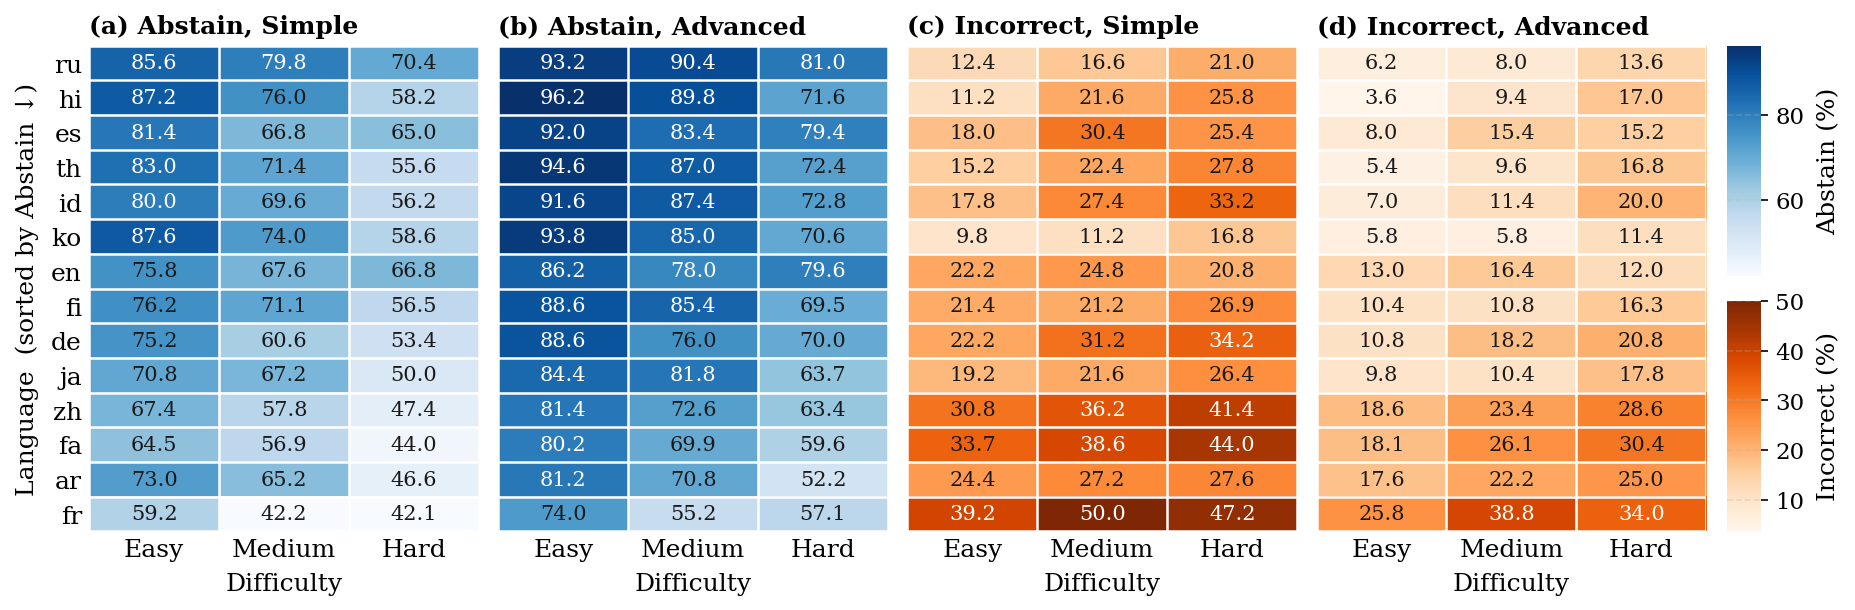

In [9]:
lang_rates = {lbl: {p: df_main[df_main.prompt == p].groupby(['language', 'difficulty'])['label']
                      .apply(lambda s, l=lbl: (s == l).mean() * 100).unstack()[DIFFICULTY_ORDER]
                      for p in PROMPTS} for lbl in ['ABSTAIN', 'INCORRECT']}
lang_order = lang_rates['ABSTAIN']['advanced'].mean(axis=1).sort_values(ascending=False).index.tolist()
col_labels = [DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER]
panels = [('a', 'Abstain', 'ABSTAIN', 'Blues', 'simple', 'Simple'),
          ('b', 'Abstain', 'ABSTAIN', 'Blues', 'advanced', 'Advanced'),
          ('c', 'Incorrect', 'INCORRECT', 'Oranges', 'simple', 'Simple'),
          ('d', 'Incorrect', 'INCORRECT', 'Oranges', 'advanced', 'Advanced')]
vrange = {lbl: (min(v.min().min() for v in lang_rates[lbl].values()), max(v.max().max() for v in lang_rates[lbl].values()))
          for lbl in lang_rates}

FIG5_HEIGHT = 4.15  # inches; reduced from 6.5 to save space in the paper (fonts unchanged)
fig, axes = plt.subplots(1, 4, figsize=(14.0, FIG5_HEIGHT), gridspec_kw=dict(wspace=0.05))
fig.subplots_adjust(left=0.10, right=0.87, top=0.90, bottom=0.12)
ims = {}
for ci, (letter, name, lbl, cmap, p, plabel) in enumerate(panels):
    ax = axes[ci]
    piv = lang_rates[lbl][p].loc[lang_order]
    vmin, vmax = vrange[lbl]
    ims[name] = ax.imshow(piv.values, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.grid(False)
    for i in range(len(lang_order)):
        for j in range(3):
            val = piv.iloc[i, j]
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=10,
                    color='white' if val > vmin + (vmax - vmin) * 0.65 else '#1a1a1a')
    ax.set_xticks(np.arange(3))
    ax.set_xticklabels(col_labels, fontsize=12)
    ax.set_xlabel('Difficulty', labelpad=5, fontsize=12)
    ax.tick_params(length=0)
    ax.set_frame_on(False)
    ax.set_yticks(np.arange(len(lang_order)))
    if ci == 0:
        ax.set_yticklabels(lang_order, fontsize=12)
        ax.set_ylabel('Language  (sorted by Abstain ↓)', labelpad=6, fontsize=12)
    else:
        ax.set_yticklabels([])
    ax.set_title(f'({letter}) {name}, {plabel}', fontsize=12, fontweight='bold', pad=6, loc='left')
    for x in np.arange(-0.5, 3, 1):
        ax.axvline(x, color='white', lw=1.2, zorder=3)
    for y in np.arange(-0.5, len(lang_order), 1):
        ax.axhline(y, color='white', lw=1.2, zorder=3)
for label, name, (bottom, height) in [('Abstain (%)', 'Abstain', (0.53, 0.37)), ('Incorrect (%)', 'Incorrect', (0.12, 0.37))]:
    cb = fig.colorbar(ims[name], cax=fig.add_axes([0.88, bottom, 0.016, height]))
    cb.set_label(label, fontsize=12, labelpad=6)
    cb.ax.tick_params(labelsize=11)
    cb.outline.set_visible(False)
fig.savefig(OUT_FIGS / 'fig5_language_heatmap.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig5_language_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
rows = []
for lang in sorted(eval_df['language'].unique()):
    pos = np.flatnonzero(QUERIES.get_level_values('language') == lang)
    idx = np.random.default_rng(SEED).integers(0, len(pos), size=(N_BOOT, len(pos)))
    for p in PROMPTS:
        row = {'language': lang, 'prompt': p}
        for lbl in ['ABSTAIN', 'INCORRECT']:
            e = {d: mean_est([col_est(W_main[lbl][(m, p, d)].to_numpy()[pos], idx) for m in MODEL_ORDER]) for d in DIFFICULTY_ORDER}
            diff = e['hard'] - e['easy']
            row[f'{lbl}_hard_minus_easy'], row[f'{lbl}_sig'], row[f'{lbl}_point'] = diff.fmt(), diff.significant, diff.point
        rows.append(row)
by_lang = pd.DataFrame(rows)
by_lang.drop(columns=['ABSTAIN_point', 'INCORRECT_point']).to_csv(OUT_TABLES / 'hard_minus_easy_by_language.csv', index=False)
print(by_lang.drop(columns=['ABSTAIN_point', 'INCORRECT_point']).to_string(index=False))
inc_up = by_lang.groupby('language')['INCORRECT_point'].apply(lambda s: (s > 0).all()).sum()
print(f"\nAbstention decrease significant: {by_lang.ABSTAIN_sig.sum()}/28 language × prompt cells")
print(f"Incorrect increase significant: {by_lang.INCORRECT_sig.sum()}/28; point estimate positive under both prompts in {inc_up}/14 languages")

language   prompt ABSTAIN_hard_minus_easy  ABSTAIN_sig INCORRECT_hard_minus_easy  INCORRECT_sig
      ar   simple    -26.4 [-34.6, -18.6]         True           3.2 [-3.4, 9.6]          False
      ar advanced    -29.0 [-36.4, -21.6]         True           7.4 [1.2, 13.0]           True
      de   simple    -21.8 [-30.0, -13.2]         True          12.0 [3.8, 20.0]           True
      de advanced    -18.6 [-26.8, -10.4]         True          10.0 [3.2, 17.4]           True
      en   simple      -9.0 [-17.6, -2.0]         True          -1.4 [-8.6, 6.0]          False
      en advanced       -6.6 [-14.8, 0.2]        False          -1.0 [-7.6, 5.2]          False
      es   simple     -16.4 [-24.8, -8.2]         True           7.4 [0.2, 14.6]           True
      es advanced     -12.6 [-20.2, -6.0]         True           7.2 [1.2, 13.4]           True
      fa   simple    -20.5 [-30.2, -10.6]         True          10.3 [0.6, 19.3]           True
      fa advanced    -20.7 [-30.8, -10.8

## Robustness with the gold-only control

The same gold passage is used for a query in all conditions. Gold+distractor labels are the three-judge majority; gold-only labels come from the single judge.

In [11]:
rows = []
for m in OPEN_MODELS:
    for p in PROMPTS:
        row = {'model': m, 'prompt': p}
        for lbl in LABELS:
            row[f'gold_{lbl[0]}'] = round(gold(lbl, m, p).point, 1)
            for d in DIFFICULTY_ORDER:
                row[f'{d}_{lbl[0]}'] = round(rob(lbl, m, p, d).point, 1)
        rows.append(row)
tbl_rob = pd.DataFrame(rows)
tbl_rob.to_csv(OUT_TABLES / 'table4_robustness.csv', index=False)
hw_rob = max(max((gold(l, m, p).hi - gold(l, m, p).lo) / 2, *[(rob(l, m, p, d).hi - rob(l, m, p, d).lo) / 2 for d in DIFFICULTY_ORDER])
             for l in LABELS for m in OPEN_MODELS for p in PROMPTS)
print(tbl_rob.to_string(index=False))
print(f'Table 4: max 95% CI half-width = {hw_rob:.2f} pp')

lines = [r'\begin{table*}[t]', r'\centering',
         r'\caption{Robustness results (gold-only and distractor+gold) for the two open-weight models. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. '
         r'Values are percentages of the LLMs-as-a-Judge majority-vote label (a single gpt-5.4-mini judge for gold-only); '
         rf'all CI half-widths are below {np.ceil(hw_rob * 10) / 10:.1f}\,pp. P: S\,=\,Simple, Adv\,=\,Advanced.}}',
         r'\label{tab:robustness}', r'\setlength{\tabcolsep}{4pt}', r'\begin{tabular}{ll ccc ccc ccc ccc}', r'\toprule',
         r'& & \multicolumn{3}{c}{\textbf{Gold only}} & \multicolumn{3}{c}{\textbf{+ Easy}} & \multicolumn{3}{c}{\textbf{+ Medium}} & \multicolumn{3}{c}{\textbf{+ Hard}} \\',
         r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}\cmidrule(lr){12-14}',
         r'\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C & A & I & C \\', r'\midrule']
for mi, m in enumerate(OPEN_MODELS):
    for pi, p in enumerate(PROMPTS):
        r = tbl_rob[(tbl_rob.model == m) & (tbl_rob.prompt == p)].iloc[0]
        vals = [r[f'{c}_{l[0]}'] for c in ['gold'] + DIFFICULTY_ORDER for l in LABELS]
        if pi == 0:
            lines.append(f'\\multirow{{2}}{{*}}{{{MODEL_LATEX[m]}}}')
        lines.append(f"  & {'S' if p == 'simple' else 'Adv'} & " + ' & '.join(f'{v:.1f}' for v in vals) + r' \\')
        if pi == 1 and mi < len(OPEN_MODELS) - 1:
            lines.append(r'\midrule')
lines += [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
(OUT_TABLES / 'table4_robustness.tex').write_text('\n'.join(lines))
print('\n'.join(lines))

      model   prompt  gold_A  easy_A  medium_A  hard_A  gold_I  easy_I  medium_I  hard_I  gold_C  easy_C  medium_C  hard_C
 gemma4:26b   simple    16.1    18.4      17.0    17.2     7.7    10.8      13.7    16.2    76.1    70.8      69.3    66.7
 gemma4:26b advanced    18.6    19.3      18.4    18.9     7.5    10.9      13.3    13.9    73.9    69.8      68.3    67.1
qwen3.6:27b   simple    17.7    16.9      16.4    16.6     5.4     9.9      11.7    12.2    76.9    73.2      71.9    71.2
qwen3.6:27b advanced    25.9    25.9      26.1    24.5     3.3     6.7       8.4     9.7    70.8    67.3      65.5    65.8
Table 4: max 95% CI half-width = 2.64 pp
\begin{table*}[t]
\centering
\caption{Robustness results (gold-only and distractor+gold) for the two open-weight models. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. Values are percentages of the LLMs-as-a-Judge majority-vote label (a single gpt-5.4-mini judge for gold-only); all CI half-widths are below 2.7\,pp. P: S\,=\,Simple, Adv\,=\,Ad

In [12]:
def transition(m, p, d, to='INCORRECT'):
    """Share of queries answered CORRECT with the gold passage alone that become `to` once the distractor is added."""
    gc = W_gold['CORRECT'][(m, p)].to_numpy()
    x = W_rob[to][(m, p, d)].to_numpy()
    ok = ~np.isnan(gc) & ~np.isnan(x)
    num, den = np.where(ok, gc * x, np.nan), np.where(ok, gc, np.nan)
    return col_est(num) / col_est(den) * 100

rows = []
for m in OPEN_MODELS:
    for p in PROMPTS:
        row = {'model': m, 'prompt': p}
        for d in DIFFICULTY_ORDER:
            row[f'dI_{d}'] = (rob('INCORRECT', m, p, d) - gold('INCORRECT', m, p)).fmt()
            row[f'dC_{d}'] = (rob('CORRECT', m, p, d) - gold('CORRECT', m, p)).fmt()
            row[f'CtoI_{d}'] = transition(m, p, d).fmt()
        hi = rob('INCORRECT', m, p, 'hard') - rob('INCORRECT', m, p, 'easy')
        hc = rob('CORRECT', m, p, 'hard') - rob('CORRECT', m, p, 'easy')
        ht = transition(m, p, 'hard') - transition(m, p, 'easy')
        row.update({'I_hard_minus_easy': hi.fmt(), 'I_sig': hi.significant,
                    'C_hard_minus_easy': hc.fmt(), 'C_sig': hc.significant,
                    'CtoI_hard_minus_easy': ht.fmt(), 'CtoI_sig': ht.significant})
        rows.append(row)
rob_stats = pd.DataFrame(rows)
rob_stats.to_csv(OUT_TABLES / 'robustness_vs_gold_only.csv', index=False)
print(rob_stats.T.to_string())

rng_ = lambda vals: f'{min(vals):.1f}–{max(vals):.1f}'
print('\nRanges over the 4 model × prompt pairs (§5.3):')
for lbl in LABELS:
    print(f'  gold only {lbl:9s}: {rng_([gold(lbl, m, p).point for m in OPEN_MODELS for p in PROMPTS])}%')
for d in DIFFICULTY_ORDER:
    di = [(rob('INCORRECT', m, p, d) - gold('INCORRECT', m, p)).point for m in OPEN_MODELS for p in PROMPTS]
    dc = [(rob('CORRECT', m, p, d) - gold('CORRECT', m, p)).point for m in OPEN_MODELS for p in PROMPTS]
    ct = [transition(m, p, d).point for m in OPEN_MODELS for p in PROMPTS]
    print(f'  +{d:6s}: ΔIncorrect {rng_(di)} pp   ΔCorrect {rng_(dc)} pp   Correct→Incorrect {rng_(ct)}%')
for m in OPEN_MODELS:
    da = [(rob('ABSTAIN', m, 'advanced', d) - rob('ABSTAIN', m, 'simple', d)).point for d in DIFFICULTY_ORDER]
    print(f'  {m}: abstention Advanced − Simple with gold+distractor {rng_(da)} pp; '
          f"gold-only abstention simple {gold('ABSTAIN', m, 'simple').point:.1f}% vs advanced {gold('ABSTAIN', m, 'advanced').point:.1f}%")

                                       0                  1                  2                  3
model                         gemma4:26b         gemma4:26b        qwen3.6:27b        qwen3.6:27b
prompt                            simple           advanced             simple           advanced
dI_easy                   3.1 [1.1, 4.9]     3.4 [1.4, 5.1]     4.4 [2.7, 5.9]     3.4 [2.0, 4.7]
dC_easy                -5.4 [-7.3, -3.2]  -4.1 [-5.9, -2.4]  -3.6 [-5.3, -1.8]  -3.5 [-5.2, -1.7]
CtoI_easy                 7.9 [6.3, 9.5]     7.1 [5.7, 8.7]     6.8 [5.3, 8.4]     5.2 [3.8, 6.5]
dI_medium                 6.0 [3.9, 7.9]     5.8 [3.9, 7.7]     6.3 [4.4, 8.2]     5.2 [3.4, 6.8]
dC_medium              -6.9 [-8.8, -4.7]  -5.7 [-7.5, -3.7]  -5.0 [-6.8, -3.2]  -5.3 [-7.2, -3.5]
CtoI_medium             10.0 [8.2, 11.9]    9.6 [7.9, 11.4]    8.3 [6.7, 10.0]     6.5 [5.0, 8.1]
dI_hard                  8.4 [6.4, 10.6]     6.4 [4.5, 8.5]     6.8 [4.9, 8.6]     6.4 [4.8, 8.1]
dC_hard             

  +hard  : ΔIncorrect 6.4–8.4 pp   ΔCorrect -9.5–-5.0 pp   Correct→Incorrect 8.1–12.0%
  gemma4:26b: abstention Advanced − Simple with gold+distractor 0.9–1.8 pp; gold-only abstention simple 16.1% vs advanced 18.6%
  qwen3.6:27b: abstention Advanced − Simple with gold+distractor 7.9–9.7 pp; gold-only abstention simple 17.7% vs advanced 25.9%


## Relevance-label provenance

Downloads the dev qrels of `datalama/miracl-hard-negatives` (the dataset used) and of the original `miracl/miracl`, and checks three things:
1. the Hard Negatives labels are the original human MIRACL judgments;
2. what share of the retrieved pool is judged;
3. every distractor carries an explicit human label 0.

In [13]:
from huggingface_hub import hf_hub_download

rows, per_query = [], []
for lang in sorted(eval_df['language'].unique()):
    hn = pd.read_parquet(hf_hub_download('datalama/miracl-hard-negatives', f'{lang}/dev-00000-of-00001.parquet', repo_type='dataset'))
    hn = hn.rename(columns={'query-id': 'query_id', 'corpus-id': 'distractor_id'}).astype({'query_id': str, 'distractor_id': str})
    corpus = set(pd.read_parquet(hf_hub_download('datalama/miracl-hard-negatives', f'corpus-{lang}/corpus-00000-of-00001.parquet',
                                                 repo_type='dataset'), columns=['_id'])['_id'].astype(str))
    mq = pd.read_csv(hf_hub_download('miracl/miracl', f'miracl-v1.0-{lang}/qrels/qrels.miracl-v1.0-{lang}-dev.tsv', repo_type='dataset'),
                     sep='\t', header=None, names=['query_id', 'q0', 'distractor_id', 'rel'], dtype=str)
    mq['rel'] = mq['rel'].astype(int)
    cmp = hn.merge(mq, on=['query_id', 'distractor_id'], how='left')
    ev = eval_df[eval_df.language == lang].merge(mq, on=['query_id', 'distractor_id'], how='left')
    rows.append({'language': lang, 'hn_pairs': len(hn), 'hn_not_in_miracl': int(cmp['rel'].isna().sum()),
                 'label_disagreements': int((cmp['rel'].notna() & (cmp['score'] != cmp['rel'])).sum()),
                 'judged_share_of_pool_%': 100 * len(set(hn['distractor_id']) & corpus) / len(corpus),
                 'distractors': len(ev), 'distractors_label0': int((ev['rel'] == 0).sum()),
                 'distractors_in_pool': int(ev['distractor_id'].isin(corpus).sum())})
    per_query.append(hn.groupby('query_id').size())
prov = pd.DataFrame(rows)
prov.to_csv(OUT_TABLES / 'label_provenance.csv', index=False)
print(prov.round(1).to_string(index=False))
t = prov.sum(numeric_only=True)
print(f"\nHard Negatives qrels: {int(t.hn_pairs):,} pairs, {int(t.hn_not_in_miracl)} not in MIRACL, {int(t.label_disagreements)} label disagreements")
print(f"Judged share of the retrieved pool: {prov['judged_share_of_pool_%'].min():.1f}–{prov['judged_share_of_pool_%'].max():.1f}%; "
      f"median judged passages per query: {pd.concat(per_query).median():.0f}")
print(f"Distractors: {int(t.distractors):,}; with explicit label 0: {int(t.distractors_label0):,}; in the retrieved pool: {int(t.distractors_in_pool):,}")

language  hn_pairs  hn_not_in_miracl  label_disagreements  judged_share_of_pool_%  distractors  distractors_label0  distractors_in_pool
      ar     10081                 0                    0                     4.4          300                 300                  300
      de      3144                 0                    0                     3.5          300                 300                  300
      en      8350                 0                    0                     4.1          300                 300                  300
      es      6443                 0                    0                     3.8          300                 300                  300
      fa      6571                 0                    0                     3.9          300                 300                  300
      fi      9436                 0                    0                     4.0          300                 300                  300
      fr      3429                 0            